In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import io
import pandas as pd

from pathlib import Path

base_dir = Path.cwd()
REPORTS_PATH = base_dir / "output"
subtypes_report_path = REPORTS_PATH / "subtypes_report.csv"

FIGSIZE = (9, 3) #(18, 8)
FONTSIZE = 10
FONTSIZE_SM = 8

In [6]:
# load subtypes report with pandas
subtypes_report = pd.read_csv(subtypes_report_path)
# Keep only Subtype, DNAm samples, GEX samples and Bimodal samples columns
subtypes_report = subtypes_report[["Subtype", "DNAm samples", "GEX samples", "Bimodal samples"]]
subtypes_report

,Subtype,DNAm samples,GEX samples,Bimodal samples
0,"AML, KMT2A-r",344,514,295
1,"AML, RUNX1::RUNX1T1",248,361,220
2,"AML, CBFB::MYH11",181,168,83
3,"AML, NPM1alt",186,226,165
4,"AML, NUP98-r",99,97,31
5,"AML, CEBPAalt",78,113,71
6,"AML, CBFA2T3::GLIS2",32,36,13
7,"AML, DEK::NUP214",27,44,27
8,"AML, APL-PML::RARA",23,20,14
9,"AML, ETV6-r",23,11,9


In [7]:
# Format each row as a tuple: ('AML, KMT2A-r', 351, 521, 302)
subtypes_report_tuples = list(subtypes_report.itertuples(index=False, name=None))
# Remove totals row
subtypes_report_tuples = [t for t in subtypes_report_tuples if t[0] != "TOTALS"]
data = subtypes_report_tuples
data

[('AML, KMT2A-r', 344, 514, 295),
 ('AML, RUNX1::RUNX1T1', 248, 361, 220),
 ('AML, CBFB::MYH11', 181, 168, 83),
 ('AML, NPM1alt', 186, 226, 165),
 ('AML, NUP98-r', 99, 97, 31),
 ('AML, CEBPAalt', 78, 113, 71),
 ('AML, CBFA2T3::GLIS2', 32, 36, 13),
 ('AML, DEK::NUP214', 27, 44, 27),
 ('AML, APL-PML::RARA', 23, 20, 14),
 ('AML, ETV6-r', 23, 11, 9),
 ('AML, KAT6A-r', 11, 12, 7),
 ('AML, FUS::ERG', 8, 7, 5),
 ('AML, PICALM::MLLT10', 9, 4, 4),
 ('B-ALL, high hyperdiploid', 330, 559, 45),
 ('B-ALL, ETV6::RUNX1', 284, 462, 31),
 ('B-ALL, BCR::ABL1-like', 20, 382, 16),
 ('B-ALL, KMT2A-r', 62, 219, 14),
 ('B-ALL, PAX5alt', 67, 219, 46),
 ('B-ALL, DUX4-r', 32, 176, 31),
 ('B-ALL, BCR::ABL1', 25, 139, 10),
 ('B-ALL, TCF3::PBX1', 37, 126, 10),
 ('B-ALL, hypodiploid', 0, 124, 0),
 ('B-ALL, ZNF384-r', 21, 84, 21),
 ('B-ALL, ETV6::RUNX1-like', 21, 69, 17),
 ('B-ALL, MEF2D-r', 9, 57, 8),
 ('B-ALL, iAMP21', 22, 51, 15),
 ('B-ALL, PAX5 P80R', 8, 38, 4),
 ('B-ALL, NUTM1-r', 4, 18, 3),
 ('B-ALL, MYC-r', 0

Saved.


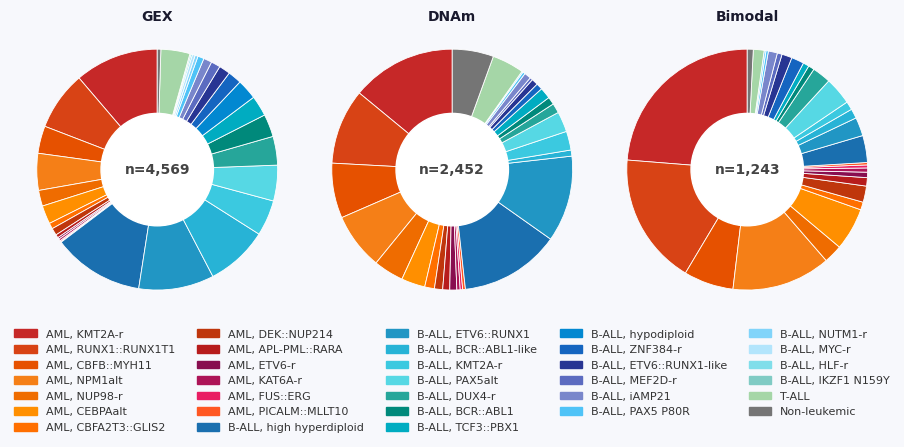

In [8]:
# ── Data ──────────────────────────────────────────────────────────────────────

subtypes  = [r[0] for r in data]
dnam_vals = [r[1] for r in data]
gex_vals  = [r[2] for r in data]
bim_vals  = [r[3] for r in data]

# ── Color palettes ────────────────────────────────────────────────────────────
# Cool blues/teals for ALL subtypes
cool_base = [
    "#1a6faf","#2196c4","#27b3d6","#3bc9e0","#56d8e4",
    "#26a69a","#00897b","#00acc1","#0288d1","#1565c0",
    "#283593","#5c6bc0","#7986cb","#4fc3f7","#81d4fa",
    "#b3e5fc","#80deea","#80cbc4","#a5d6a7",
]

# Warm reds/oranges/yellows for AML subtypes
warm_base = [
    "#c62828","#d84315","#e65100","#f57f17","#ef6c00",
    "#ff8f00","#ff6f00","#bf360c","#b71c1c","#880e4f",
    "#ad1457","#e91e63","#ff5722","#ff7043","#ff8a65",
    "#ffa726",
]

# Grays for everything else
gray_base = [
    "#757575","#9e9e9e","#bdbdbd",
]

def assign_colors(subtypes, warm_base, cool_base, gray_base):
    aml_idx = cool_idx = gray_idx = 0
    colors = []
    for s in subtypes:
        if s.startswith("AML"):
            colors.append(warm_base[aml_idx % len(warm_base)])
            aml_idx += 1
        elif s.startswith("B-ALL") or s.startswith("T-ALL"):
            colors.append(cool_base[cool_idx % len(cool_base)])
            cool_idx += 1
        else:
            colors.append(gray_base[gray_idx % len(gray_base)])
            gray_idx += 1
    return colors

colors = assign_colors(subtypes, warm_base, cool_base, gray_base)

# ── Helper: draw one pie ──────────────────────────────────────────────────────
def draw_pie(ax, values, title, colors, subtypes):
    # Drop zero-value slices for cleanliness
    nonzero = [(v, c, s) for v, c, s in zip(values, colors, subtypes) if v > 0]
    vals, cols, labs = zip(*nonzero)

    wedges, _ = ax.pie(
        vals,
        colors=cols,
        startangle=90,
        wedgeprops=dict(linewidth=0.6, edgecolor="white"),
        radius=1.5,
    )

    ax.set_title(title, fontsize=FONTSIZE, fontweight="bold",
                 color="#1a1a2e", pad=35)

    # Donut hole
    centre = plt.Circle((0, 0), 0.7, color="white", zorder=3)
    ax.add_patch(centre)

    total = sum(vals)
    ax.text(0, 0, f"n={total:,}", ha="center", va="center",
            fontsize=FONTSIZE, color="#444", fontweight="bold")

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE)
fig.patch.set_facecolor("#f7f8fc")

draw_pie(axes[0], gex_vals,  "GEX",     colors, subtypes)
draw_pie(axes[1], dnam_vals, "DNAm",    colors, subtypes)
draw_pie(axes[2], bim_vals,  "Bimodal", colors, subtypes)

# ── Shared legend ─────────────────────────────────────────────────────────────
legend_handles = [
    mpatches.Patch(color=c, label=s)
    for s, c in zip(subtypes, colors)
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    fontsize=FONTSIZE_SM,
    frameon=False,
    bbox_to_anchor=(0.5, -0.5),
    labelcolor="#333",
)

# fig.subplots_adjust(wspace=0.6)

plt.tight_layout(rect=[0, 0, 1, 0.95])  # leave space for legend
plt.savefig(REPORTS_PATH / "subtypes_pie_charts.svg",
            dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())
print("Saved.")